# Predicting Recurrent Myocardial Infarction During Hospitalization
## Comparative benchmarking: KNN, Naive Bayes, linear and nonlinear models

**Data:** UCI *Myocardial Infarction Complications* (Golovenkin et al.), 1,700 patients, 111 candidate predictors, 12 complication outcomes.

**Prediction question:** at the time of hospital admission, which patients are at high risk of a **recurrent MI** (`REC_IM = 1`) during the hospital stay?

Recurrent MI is far less studied than mortality or heart failure in this dataset, yet it is clinically actionable: high-risk patients could get closer monitoring, earlier angiography or intensified antithrombotic therapy.

**Workflow (following the course notes):**
1. Define the outcome and a *leakage-safe* predictor set (admission-time only).
2. Split once into training (80%) and a held-out test set (20%), stratified, `random_state=2026`.
3. Build every model as a `Pipeline` so imputation and scaling are learned inside each CV fold.
4. Tune hyperparameters with 5-fold CV; estimate honest performance with **nested CV**; select the best models on nested CV, *not* on the test set.
5. Evaluate on the held-out test set with 12 metrics, ROC/PR/calibration curves and bootstrap CIs.
6. SHAP feature importance for the best three algorithms.
7. Diagnose data leakage and over/underfitting.

*This model is for teaching risk stratification, not for clinical decisions.*

In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_val_predict, learning_curve,
                                     validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             accuracy_score, balanced_accuracy_score, recall_score, precision_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve, precision_recall_curve,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay

warnings.filterwarnings("ignore")
SEED = 2026
np.random.seed(SEED)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load the data and name the columns
`mi.csv` was saved from `MI.data` with `?` converted to missing. Column names follow the UCI codebook.

In [2]:
COLS = ["ID","AGE","SEX","INF_ANAM","STENOK_AN","FK_STENOK","IBS_POST","IBS_NASL","GB","SIM_GIPERT",
 "DLIT_AG","ZSN_A","nr_11","nr_01","nr_02","nr_03","nr_04","nr_07","nr_08","np_01","np_04","np_05",
 "np_07","np_08","np_09","np_10","endocr_01","endocr_02","endocr_03","zab_leg_01","zab_leg_02",
 "zab_leg_03","zab_leg_04","zab_leg_06","S_AD_KBRIG","D_AD_KBRIG","S_AD_ORIT","D_AD_ORIT","O_L_POST",
 "K_SH_POST","MP_TP_POST","SVT_POST","GT_POST","FIB_G_POST","ant_im","lat_im","inf_im","post_im",
 "IM_PG_P","ritm_ecg_p_01","ritm_ecg_p_02","ritm_ecg_p_04","ritm_ecg_p_06","ritm_ecg_p_07",
 "ritm_ecg_p_08","n_r_ecg_p_01","n_r_ecg_p_02","n_r_ecg_p_03","n_r_ecg_p_04","n_r_ecg_p_05",
 "n_r_ecg_p_06","n_r_ecg_p_08","n_r_ecg_p_09","n_r_ecg_p_10","n_p_ecg_p_01","n_p_ecg_p_03",
 "n_p_ecg_p_04","n_p_ecg_p_05","n_p_ecg_p_06","n_p_ecg_p_07","n_p_ecg_p_08","n_p_ecg_p_09",
 "n_p_ecg_p_10","n_p_ecg_p_11","n_p_ecg_p_12","fibr_ter_01","fibr_ter_02","fibr_ter_03",
 "fibr_ter_05","fibr_ter_06","fibr_ter_07","fibr_ter_08","GIPO_K","K_BLOOD","GIPER_NA","NA_BLOOD",
 "ALT_BLOOD","AST_BLOOD","KFK_BLOOD","L_BLOOD","ROE","TIME_B_S","R_AB_1_n","R_AB_2_n","R_AB_3_n",
 "NA_KB","NOT_NA_KB","LID_KB","NITR_S","NA_R_1_n","NA_R_2_n","NA_R_3_n","NOT_NA_1_n","NOT_NA_2_n",
 "NOT_NA_3_n","LID_S_n","B_BLOK_S_n","ANT_CA_S_n","GEPAR_S_n","ASP_S_n","TIKL_S_n","TRENT_S_n",
 "FIBR_PREDS","PREDS_TAH","JELUD_TAH","FIBR_JELUD","A_V_BLOK","OTEK_LANC","RAZRIV","DRESSLER",
 "ZSN","REC_IM","P_IM_STEN","LET_IS"]

# Short readable labels for the features that tend to matter (used in SHAP plots)
LABELS = {
 "AGE":"Age", "SEX":"Sex (1=male)", "INF_ANAM":"Number of prior MIs", "STENOK_AN":"Angina history",
 "FK_STENOK":"Angina functional class", "IBS_POST":"CHD in recent weeks", "GB":"Essential hypertension",
 "DLIT_AG":"Duration of hypertension", "ZSN_A":"Chronic heart failure (history)",
 "S_AD_ORIT":"Systolic BP (ICU)", "D_AD_ORIT":"Diastolic BP (ICU)", "S_AD_KBRIG":"Systolic BP (EMS)",
 "D_AD_KBRIG":"Diastolic BP (EMS)", "O_L_POST":"Pulmonary edema at ICU", "K_SH_POST":"Cardiogenic shock at ICU",
 "MP_TP_POST":"AF/flutter at ICU", "ant_im":"Anterior MI extent", "lat_im":"Lateral MI extent",
 "inf_im":"Inferior MI extent", "post_im":"Posterior MI extent", "IM_PG_P":"Right ventricular MI",
 "K_BLOOD":"Serum potassium", "NA_BLOOD":"Serum sodium", "ALT_BLOOD":"ALT", "AST_BLOOD":"AST",
 "L_BLOOD":"White blood cell count", "ROE":"ESR", "TIME_B_S":"Time from onset to hospital",
 "R_AB_1_n":"Pain relapse, day 1", "NA_KB":"Opioids by EMS", "NOT_NA_KB":"NSAIDs by EMS", "LID_KB":"Lidocaine by EMS",
 "NITR_S":"Liquid nitrates (ICU)", "NA_R_1_n":"Opioids in ICU, day 1", "NOT_NA_1_n":"NSAIDs in ICU, day 1",
 "LID_S_n":"Lidocaine (ICU)", "B_BLOK_S_n":"Beta-blockers (ICU)", "ANT_CA_S_n":"Calcium channel blockers (ICU)",
 "GEPAR_S_n":"Heparin (ICU)", "ASP_S_n":"Aspirin (ICU)", "TIKL_S_n":"Ticlopidine (ICU)", "TRENT_S_n":"Trental (ICU)",
 "ritm_ecg_p_01":"Sinus rhythm 60–90 bpm (ECG)", "ritm_ecg_p_07":"Sinus tachycardia >90 bpm (ECG)",
 "ritm_ecg_p_02":"Atrial fibrillation (ECG)", "ritm_ecg_p_08":"Sinus bradycardia (ECG)", "endocr_01":"Diabetes", "endocr_02":"Obesity", "zab_leg_01":"Chronic bronchitis", "SIM_GIPERT":"Symptomatic hypertension",
}

df = pd.read_csv("../data/mi.csv")
df.columns = COLS
print(df.shape)
df.head()

(1700, 124)


,ID,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,...,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,1,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,2,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,3,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,4,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,1,0,0,0
4,5,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0


## 2. Outcome and leakage-safe predictor set

**Outcome.** `REC_IM` = 1 if the patient had a recurrent myocardial infarction during hospitalization (binary).

**Columns we deliberately exclude (and why):**

| Excluded | Reason |
|---|---|
| `ID` | Row identifier, carries no clinical information — could only leak data-entry order. |
| 11 other complication outcomes (incl. death, `LET_IS`) | Other *outcomes* recorded during the same stay, unknown at admission. Using them is **target leakage**. |
| `R_AB_2_n`, `R_AB_3_n`, `NA_R_2_n`, `NA_R_3_n`, `NOT_NA_2_n`, `NOT_NA_3_n` | Measured on hospital **days 2–3**, not available at admission (**temporal leakage**). |
| `R_AB_1_n`, `NA_R_1_n`, `NOT_NA_1_n` | Measured during the **first 24 h**; also not available at admission. The UCI codebook excludes all nine of these for admission-time prediction. |

Section 8 shows what happens if we ignore this.

In [3]:
OUTCOME = "REC_IM"
df["Y"] = df[OUTCOME].astype(int)
df["DEATH"] = (df["LET_IS"] > 0).astype(int)

OUTCOMES = COLS[112:124]
POST_ADMISSION = ["R_AB_1_n","R_AB_2_n","R_AB_3_n","NA_R_1_n","NA_R_2_n","NA_R_3_n",
                  "NOT_NA_1_n","NOT_NA_2_n","NOT_NA_3_n"]
ALL_INPUTS = COLS[1:112]                                   # 111 candidate predictors
ADMISSION_INPUTS = [c for c in ALL_INPUTS if c not in POST_ADMISSION]

print("Recurrent MI cases:", df.Y.sum(), f"({df.Y.mean():.1%})")
print("Candidate inputs:", len(ALL_INPUTS), "| admission-time inputs:", len(ADMISSION_INPUTS))
print("Duplicate IDs:", df.ID.duplicated().sum(), "| duplicate patient rows:", df[ALL_INPUTS].duplicated().sum())

Recurrent MI cases: 159 (9.4%)
Candidate inputs: 111 | admission-time inputs: 102
Duplicate IDs: 0 | duplicate patient rows: 0


### Competing risk: death
A patient who dies early has less time to have a recurrent MI recorded. We keep all patients (the clinical question is "who will re-infarct during this stay?"), but this competing risk is a limitation and is checked below.

In [4]:
pd.crosstab(df.Y.map({0: "No re-MI", 1: "Re-MI"}), df.DEATH.map({0: "Survived", 1: "Died"}), margins=True)

DEATH,Died,Survived,All
Y,,,
No re-MI,225,1316,1541
Re-MI,46,113,159
All,271,1429,1700


### Train / test split (done *before* any data-driven decision)

In [5]:
X = df[ALL_INPUTS]
y = df["Y"]
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("Train:", X_train_all.shape, f"recurrent-MI rate {y_train.mean():.3f}")
print("Test: ", X_test_all.shape, f"recurrent-MI rate {y_test.mean():.3f}")

# Drop near-empty predictors using TRAINING data only (KFK_BLOOD is ~100% missing)
miss_train = X_train_all[ADMISSION_INPUTS].isna().mean()
too_sparse = miss_train[miss_train > 0.70].index.tolist()
print("Dropped for >70% missing in training data:", too_sparse)

FEATURES = [c for c in ADMISSION_INPUTS if c not in too_sparse]
X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]

# Continuous vs coded (binary / ordinal) predictors
CONTINUOUS = [c for c in ["AGE","S_AD_KBRIG","D_AD_KBRIG","S_AD_ORIT","D_AD_ORIT","K_BLOOD",
                          "NA_BLOOD","ALT_BLOOD","AST_BLOOD","L_BLOOD","ROE"] if c in FEATURES]
CODED = [c for c in FEATURES if c not in CONTINUOUS]
print(f"{len(FEATURES)} features: {len(CONTINUOUS)} continuous, {len(CODED)} binary/ordinal")

Train: (1360, 111) recurrent-MI rate 0.093
Test:  (340, 111) recurrent-MI rate 0.094
Dropped for >70% missing in training data: ['IBS_NASL', 'KFK_BLOOD']
100 features: 11 continuous, 89 binary/ordinal


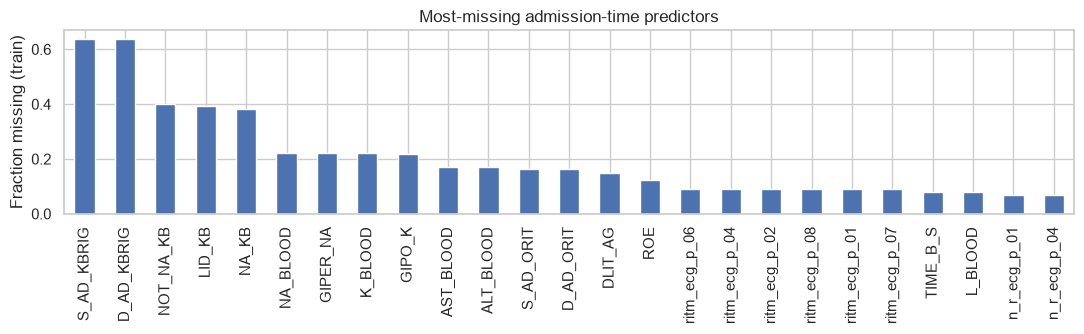

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.5))
miss_train[FEATURES].sort_values(ascending=False).head(25).plot.bar(ax=ax, color="#4C72B0")
ax.set_ylabel("Fraction missing (train)"); ax.set_title("Most-missing admission-time predictors")
plt.tight_layout(); plt.show()

## 3. Preprocessing and model pipelines

Every model shares the same leakage-free preprocessing, fit only on training folds:
* continuous predictors → median imputation → standardization
* binary/ordinal codes → most-frequent imputation → standardization

The spline model additionally expands each continuous predictor into a cubic B-spline basis (an additive, GAM-like logistic model).

| Family | Model | What is tuned |
|---|---|---|
| Similarity | KNN | k, weights, distance |
| Bayes | Gaussian Naive Bayes | variance smoothing |
| Linear | Logistic regression (ridge, L2) | C |
| Linear, sparse | Lasso logistic (L1) | C |
| Linear, sparse | Elastic-net logistic | C, L1 ratio |
| Discriminant | LDA (shrinkage) | shrinkage |
| Discriminant | QDA (shrinkage; plain QDA is singular with ~80 cases per fold) | shrinkage |
| Nonlinear | Spline logistic (additive) | knots, C |
| Nonlinear, bagging | Random forest | depth, leaf size, max features |
| Nonlinear, boosting | Gradient boosting | learning rate, depth, L2 |

In [7]:
def preprocessor(spline=False):
    cont_steps = [("impute", SimpleImputer(strategy="median"))]
    if spline:
        cont_steps.append(("spline", SplineTransformer(degree=3, n_knots=4)))
    cont_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("cont", Pipeline(cont_steps), CONTINUOUS),
        ("coded", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("scale", StandardScaler())]), CODED),
    ])

def make_pipe(clf, spline=False):
    return Pipeline([("prep", preprocessor(spline)), ("clf", clf)])

C_GRID = np.logspace(-3, 1, 9)
MODELS = {
    "KNN": (make_pipe(KNeighborsClassifier()),
            {"clf__n_neighbors": list(range(5, 76, 10)), "clf__weights": ["uniform", "distance"],
             "clf__metric": ["euclidean", "manhattan"]}),
    "Naive Bayes": (make_pipe(GaussianNB()),
            {"clf__var_smoothing": np.logspace(-9, 0, 10)}),
    "Logistic (ridge)": (make_pipe(LogisticRegression(l1_ratio=0, solver="lbfgs", max_iter=5000)),
            {"clf__C": C_GRID}),
    "Lasso logistic": (make_pipe(LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=5000)),
            {"clf__C": C_GRID}),
    "Elastic net": (make_pipe(LogisticRegression(solver="saga", max_iter=5000)),
            {"clf__C": np.logspace(-2, 0, 5), "clf__l1_ratio": [0.2, 0.5, 0.8]}),
    "LDA": (make_pipe(LinearDiscriminantAnalysis(solver="lsqr")),
            {"clf__shrinkage": [0.01, 0.1, 0.3, 0.5, 0.7, 0.9]}),
    # Only ~80 re-MI patients per CV fold vs 100 features: the class covariance matrix is singular,
    # so plain QDA fails. Ledoit-Wolf-style shrinkage toward a diagonal fixes this.
    "QDA": (make_pipe(QuadraticDiscriminantAnalysis(solver="eigen")),
            {"clf__shrinkage": [0.3, 0.5, 0.7, 0.9, 0.99]}),
    "Spline logistic": (make_pipe(LogisticRegression(l1_ratio=0, max_iter=5000), spline=True),
            {"prep__cont__spline__n_knots": [3, 5], "clf__C": np.logspace(-3, 0, 4)}),
    "Random forest": (make_pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
            {"clf__max_depth": [4, 8, None], "clf__min_samples_leaf": [3, 10],
             "clf__max_features": ["sqrt", 0.3]}),
    "Gradient boosting": (make_pipe(HistGradientBoostingClassifier(max_iter=200, random_state=SEED)),
            {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 4],
             "clf__l2_regularization": [0.0, 1.0]}),
}

## 4. Tuning and nested cross-validation (training data only)

* **Inner loop** (`GridSearchCV`, 5-fold): picks hyperparameters. Its best score is *optimistic*, because the grid was chosen to maximize it.
* **Outer loop** (5-fold, wrapping the whole grid search): gives an honest estimate of how the *tuning procedure* performs on unseen data. We rank models on this.
* **Train AUC**: refit model scored on its own training data — used to diagnose overfitting.
* **OOF threshold**: out-of-fold predictions on the training data pick a decision threshold (Youden's J), so the test set is never used for any choice.

In [8]:
import os
if os.environ.get("FAST"):
    MODELS = {k: (p, {kk: vv[:1] for kk, vv in g.items()}) for k, (p, g) in MODELS.items()}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)

def youden_threshold(y_true, prob):
    fpr, tpr, thr = roc_curve(y_true, prob)
    return float(thr[np.argmax(tpr - fpr)])

fitted, cv_rows, thresholds = {}, [], {}
for name, (pipe, grid) in MODELS.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=inner_cv, n_jobs=-1, refit=True)
    nested = cross_val_score(gs, X_train, y_train, cv=outer_cv, scoring="roc_auc", n_jobs=1)
    gs.fit(X_train, y_train)
    best = gs.best_estimator_
    oof = cross_val_predict(best, X_train, y_train, cv=inner_cv, method="predict_proba")[:, 1]
    thresholds[name] = youden_threshold(y_train, oof)
    fitted[name] = best
    cv_rows.append({
        "Model": name,
        "Train AUC": roc_auc_score(y_train, best.predict_proba(X_train)[:, 1]),
        "Inner CV AUC (tuned)": gs.best_score_,
        "Nested CV AUC": nested.mean(), "Nested CV SD": nested.std(),
        "Threshold": thresholds[name],
        "Best params": {k.replace("clf__", "").replace("prep__cont__spline__", "spline_"): v
                        for k, v in gs.best_params_.items()},
    })
    print(f"{name:<18} nested AUC {nested.mean():.3f} ± {nested.std():.3f}  ({time.time()-t0:.0f}s)")

cv_table = pd.DataFrame(cv_rows).sort_values("Nested CV AUC", ascending=False).reset_index(drop=True)
cv_table.round(3)

KNN                nested AUC 0.607 ± 0.081  (33s)
Naive Bayes        nested AUC 0.580 ± 0.036  (9s)
Logistic (ridge)   nested AUC 0.653 ± 0.038  (7s)
Lasso logistic     nested AUC 0.625 ± 0.037  (10s)
Elastic net        nested AUC 0.634 ± 0.041  (50s)
LDA                nested AUC 0.653 ± 0.039  (7s)
QDA                nested AUC 0.561 ± 0.060  (6s)
Spline logistic    nested AUC 0.648 ± 0.034  (9s)
Random forest      nested AUC 0.651 ± 0.044  (96s)
Gradient boosting  nested AUC 0.623 ± 0.023  (40s)


,Model,Train AUC,Inner CV AUC (tuned),Nested CV AUC,Nested CV SD,Threshold,Best params
0,Logistic (ridge),0.760,0.624,0.653,0.038,0.099,{'C': 0.001}
1,LDA,0.759,0.624,0.653,0.039,0.094,{'shrinkage': 0.9}
2,Random forest,0.980,0.654,0.651,0.044,0.085,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
3,Spline logistic,0.769,0.627,0.648,0.034,0.098,"{'C': 0.001, 'spline_n_knots': 3}"
4,Elastic net,0.731,0.618,0.634,0.041,0.096,"{'C': 0.03162277660168379, 'l1_ratio': 0.5}"
5,Lasso logistic,0.761,0.622,0.625,0.037,0.087,{'C': 0.1}
6,Gradient boosting,0.841,0.636,0.623,0.023,0.072,"{'l2_regularization': 1.0, 'learning_rate': 0...."
7,KNN,1.000,0.636,0.607,0.081,0.081,"{'metric': 'manhattan', 'n_neighbors': 75, 'we..."
8,Naive Bayes,0.730,0.542,0.580,0.036,1.000,{'var_smoothing': 0.01}
9,QDA,0.599,0.564,0.561,0.060,0.012,{'shrinkage': 0.99}


## 5. Held-out test-set performance (12 metrics)

Threshold-free: **ROC-AUC** (with 95% bootstrap CI), **PR-AUC**, **Brier score**, **log loss**.
At each model's training-chosen threshold: **accuracy, balanced accuracy, sensitivity, specificity, PPV, NPV, F1, MCC**.

With only ~9% cases, accuracy alone is misleading (predicting "no recurrence" for everyone scores ~91%), so balanced accuracy, MCC and PR-AUC matter more.

In [9]:
def bootstrap_auc(y_true, prob, B=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, prob = np.asarray(y_true), np.asarray(prob)
    aucs = []
    for _ in range(B):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() == y_true[idx].max():
            continue
        aucs.append(roc_auc_score(y_true[idx], prob[idx]))
    return np.percentile(aucs, [2.5, 97.5])

def evaluate(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    lo, hi = bootstrap_auc(y_true, prob)
    return {
        "ROC-AUC": roc_auc_score(y_true, prob), "AUC 95% CI": f"{lo:.3f}–{hi:.3f}",
        "PR-AUC": average_precision_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
        "Log loss": log_loss(y_true, np.clip(prob, 1e-6, 1 - 1e-6)),
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced acc": balanced_accuracy_score(y_true, pred),
        "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
        "PPV": tp / (tp + fp) if tp + fp else np.nan, "NPV": tn / (tn + fn) if tn + fn else np.nan,
        "F1": f1_score(y_true, pred), "MCC": matthews_corrcoef(y_true, pred),
    }

test_prob = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}
test_table = pd.DataFrame(
    [{"Model": n, **evaluate(y_test, test_prob[n], thresholds[n])} for n in cv_table.Model]
)
print(f"Baseline: Brier of always predicting the prevalence = {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.3f}; "
      f"PR-AUC of a random model = {y_test.mean():.3f}")
test_table.set_index("Model").round(3)

Baseline: Brier of always predicting the prevalence = 0.085; PR-AUC of a random model = 0.094


,ROC-AUC,AUC 95% CI,PR-AUC,Brier,Log loss,Accuracy,Balanced acc,Sensitivity,Specificity,PPV,NPV,F1,MCC
Model,,,,,,,,,,,,,
Logistic (ridge),0.612,0.501–0.720,0.174,0.084,0.307,0.706,0.600,0.469,0.731,0.153,0.930,0.231,0.128
LDA,0.613,0.502–0.720,0.174,0.097,0.372,0.697,0.595,0.469,0.721,0.149,0.929,0.226,0.121
Random forest,0.583,0.461–0.695,0.184,0.084,0.311,0.532,0.588,0.656,0.519,0.124,0.936,0.209,0.103
Spline logistic,0.634,0.520–0.745,0.209,0.084,0.305,0.679,0.613,0.531,0.695,0.153,0.934,0.238,0.141
Elastic net,0.585,0.473–0.689,0.152,0.084,0.307,0.638,0.562,0.469,0.656,0.124,0.922,0.196,0.076
Lasso logistic,0.603,0.491–0.712,0.165,0.084,0.306,0.559,0.588,0.625,0.552,0.127,0.934,0.211,0.104
Gradient boosting,0.556,0.445–0.656,0.143,0.085,0.312,0.491,0.495,0.500,0.490,0.092,0.904,0.156,-0.006
KNN,0.627,0.508–0.733,0.173,0.084,0.306,0.459,0.547,0.656,0.438,0.108,0.925,0.186,0.056
Naive Bayes,0.633,0.526–0.735,0.136,0.811,10.914,0.812,0.490,0.094,0.886,0.079,0.904,0.086,-0.018


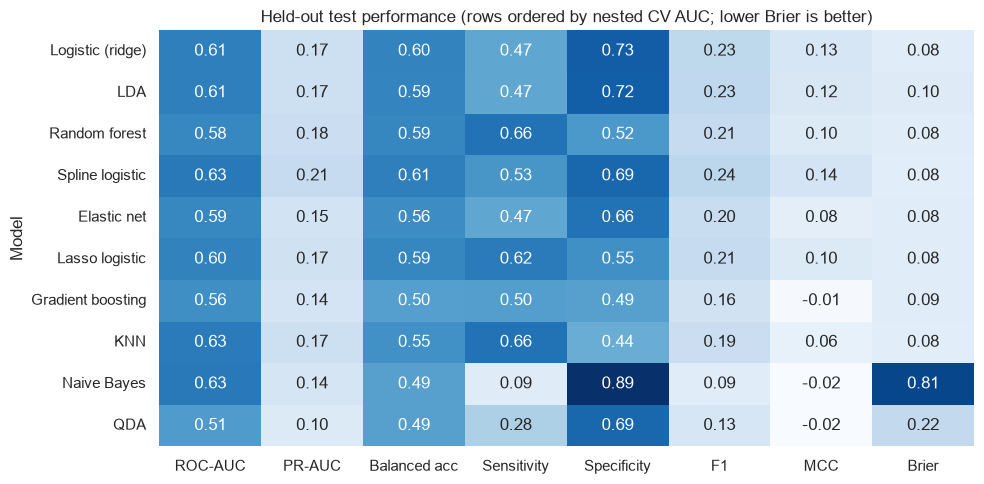

In [10]:
metric_cols = ["ROC-AUC", "PR-AUC", "Balanced acc", "Sensitivity", "Specificity", "F1", "MCC"]
heat = test_table.set_index("Model")[metric_cols + ["Brier"]].astype(float)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Held-out test performance (rows ordered by nested CV AUC; lower Brier is better)")
plt.tight_layout(); plt.show()

Best three algorithms (by nested CV AUC): ['Logistic (ridge)', 'LDA', 'Random forest']


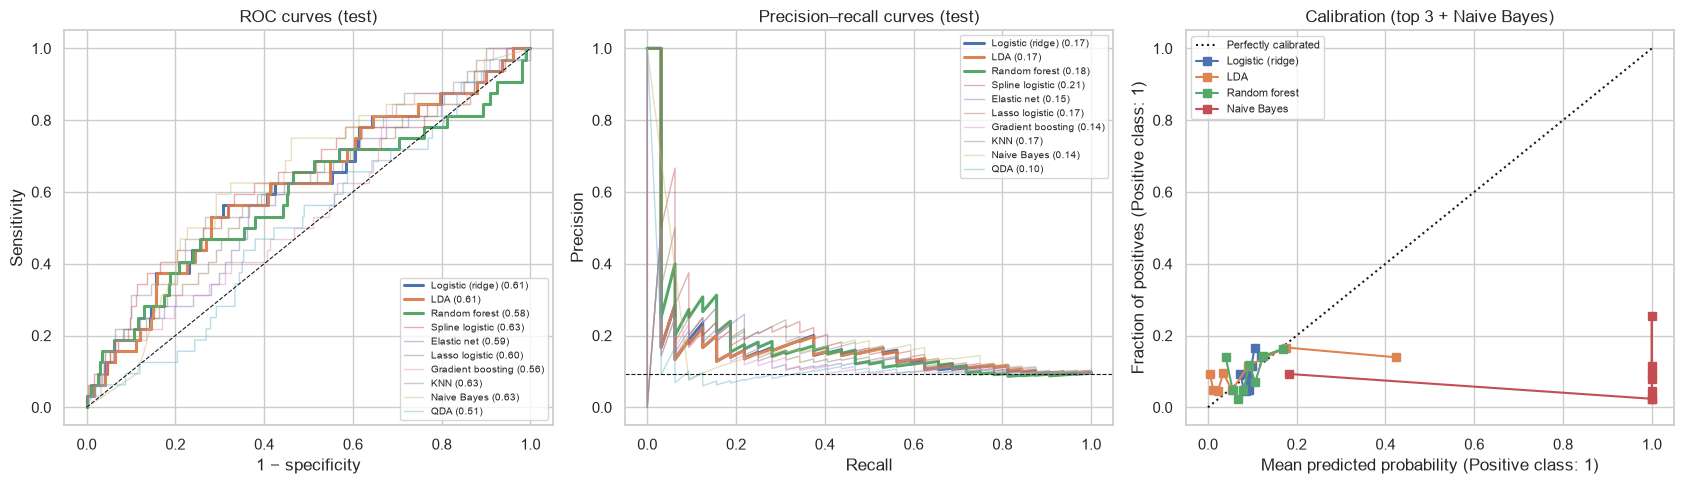

In [11]:
TOP3 = cv_table.Model.head(3).tolist()
print("Best three algorithms (by nested CV AUC):", TOP3)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for name in cv_table.Model:
    lw, alpha = (2.2, 1) if name in TOP3 else (1, 0.45)
    fpr, tpr, _ = roc_curve(y_test, test_prob[name])
    prec, rec, _ = precision_recall_curve(y_test, test_prob[name])
    axes[0].plot(fpr, tpr, lw=lw, alpha=alpha, label=f"{name} ({roc_auc_score(y_test, test_prob[name]):.2f})")
    axes[1].plot(rec, prec, lw=lw, alpha=alpha,
                 label=f"{name} ({average_precision_score(y_test, test_prob[name]):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set_title("ROC curves (test)"); axes[0].set_xlabel("1 − specificity"); axes[0].set_ylabel("Sensitivity")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=0.8); axes[1].set_title("Precision–recall curves (test)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
for ax in axes[:2]:
    ax.legend(fontsize=7, loc="lower right" if ax is axes[0] else "upper right")
for name in TOP3 + ["Naive Bayes"]:
    CalibrationDisplay.from_predictions(y_test, test_prob[name], n_bins=8, strategy="quantile",
                                        name=name, ax=axes[2])
axes[2].set_title("Calibration (top 3 + Naive Bayes)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

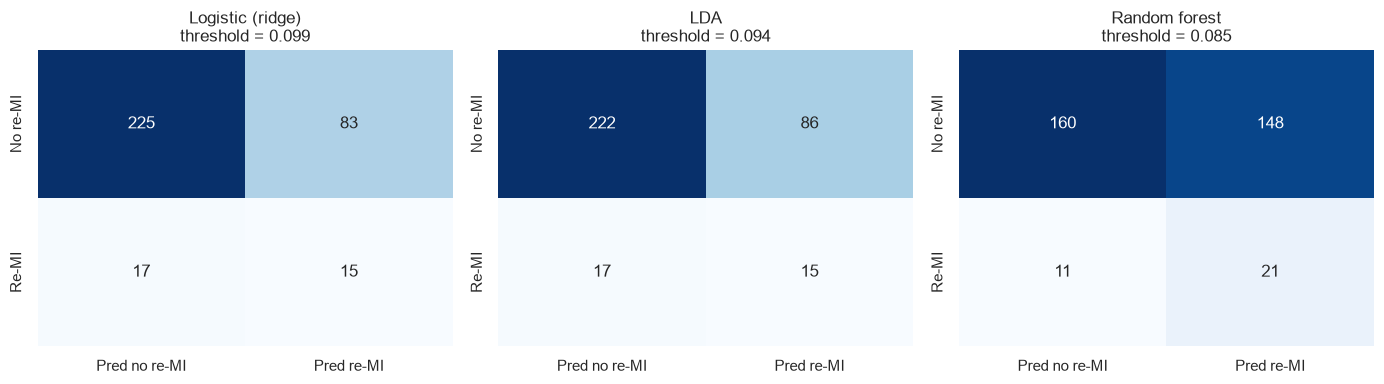

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, TOP3):
    pred = (test_prob[name] >= thresholds[name]).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred no re-MI", "Pred re-MI"], yticklabels=["No re-MI", "Re-MI"])
    ax.set_title(f"{name}\nthreshold = {thresholds[name]:.3f}")
plt.tight_layout(); plt.show()

### Interpretation — model comparison
* **Recurrent MI is hard to predict from admission data.** Every model lands between nested CV AUC 0.56 and 0.65 (mortality reached 0.89 on the same predictors). The ceiling comes from the *information in the predictors*, not from the choice of algorithm. This is irreducible error in the bias–variance decomposition.
* **The top four are statistically tied** (ridge logistic, LDA, random forest, spline logistic: nested AUC 0.648–0.653). Test AUC CIs are wide (≈0.50–0.72) because the test set has only 32 cases.
* **Simple, heavily regularized linear models do as well as or better than ensembles.** Ridge chose the strongest penalty in the grid (C = 0.001). Boosting and random forest fall off on the test set, which is typical when signal is weak and noise is easy to memorize.
* **PR-AUC of 0.15–0.21 is about 2× the 0.094 baseline.** The models find *some* enrichment, but PPV at the chosen threshold is only ~15%: roughly 1 in 7 flagged patients has a recurrence.
* **Calibration:** Brier scores (≈0.084) barely beat the no-skill prevalence model (0.085). **Naive Bayes** has a reasonable test AUC (0.63) but catastrophic probabilities (Brier 0.81, log loss 10.9). This is a clear example of good ranking with useless calibration.
* **QDA** needed covariance shrinkage just to run (~80 cases per fold vs 100 features) and is near-random, as the Bayes lecture notes warn for small classes.

## 6. SHAP feature importance for the best three algorithms

SHAP values split each patient's predicted risk into additive contributions from each predictor.
* Tree models use the exact `TreeExplainer`.
* Linear models use `LinearExplainer` (on log-odds).
* Other models (KNN, NB, LDA/QDA, splines) use the model-agnostic permutation explainer on predicted probability.

Explanations are computed on the **test set** using a **training-set** background sample. Because each predictor passes through its own imputer/scaler, SHAP values in the transformed space map one-to-one to the original predictors (except the spline model, which is explained on raw inputs).

In [13]:
bg_raw = X_train.sample(100, random_state=SEED)
explain_raw = X_test.sample(min(200, len(X_test)), random_state=SEED)
nice = lambda cols: [LABELS.get(c, c) for c in cols]

def shap_for(name, model):
    clf, prep = model.named_steps["clf"], model.named_steps["prep"]
    if isinstance(clf, (RandomForestClassifier, HistGradientBoostingClassifier)) or \
       (isinstance(clf, LogisticRegression) and name != "Spline logistic"):
        Xt = pd.DataFrame(prep.transform(explain_raw), columns=CONTINUOUS + CODED, index=explain_raw.index)
        bg = pd.DataFrame(prep.transform(bg_raw), columns=CONTINUOUS + CODED)
        if isinstance(clf, LogisticRegression):
            sv = shap.LinearExplainer(clf, bg)(Xt)
        else:
            sv = shap.TreeExplainer(clf)(Xt)
            if sv.values.ndim == 3:                      # random forest: keep positive class
                sv = sv[:, :, 1]
        # show feature values on the original scale
        return shap.Explanation(sv.values, sv.base_values, data=explain_raw[CONTINUOUS + CODED].values,
                                feature_names=nice(CONTINUOUS + CODED))
    f = lambda A: model.predict_proba(pd.DataFrame(A, columns=FEATURES))[:, 1]
    expl = shap.PermutationExplainer(f, shap.maskers.Independent(bg_raw.values),
                                     max_evals=2 * len(FEATURES) + 1, seed=SEED)
    sv = expl(explain_raw.values, silent=True)
    return shap.Explanation(sv.values, sv.base_values, data=explain_raw.values, feature_names=nice(FEATURES))

shap_values = {}
for name in TOP3:
    t0 = time.time()
    shap_values[name] = shap_for(name, fitted[name])
    print(f"{name}: SHAP done in {time.time()-t0:.0f}s")

Logistic (ridge): SHAP done in 0s
LDA: SHAP done in 20s
Random forest: SHAP done in 2s


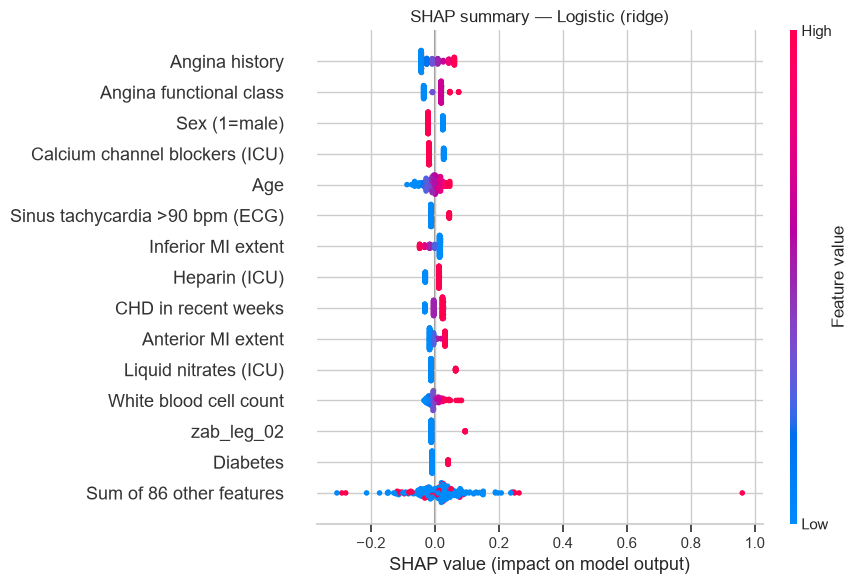

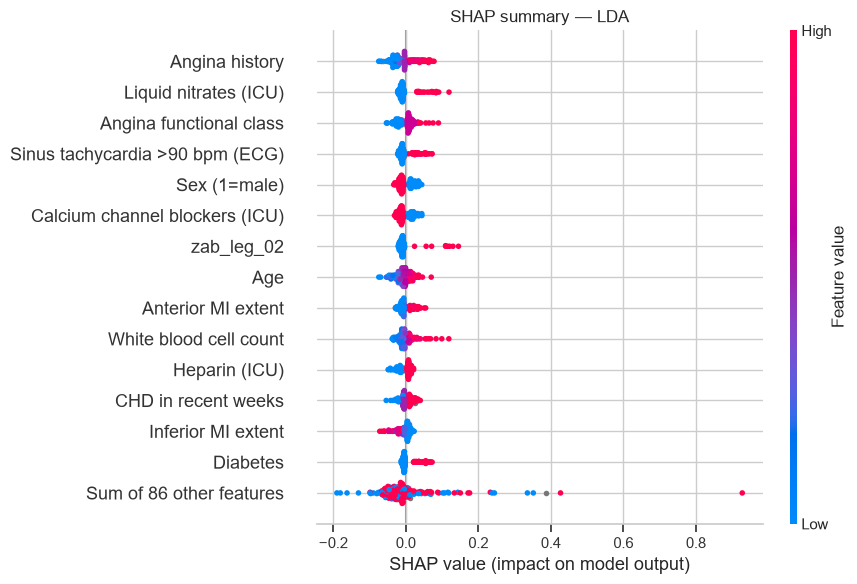

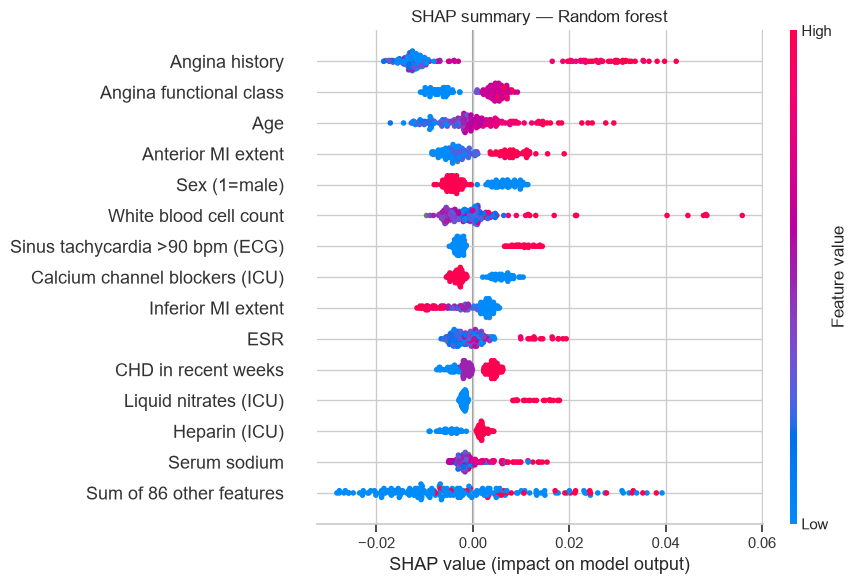

In [14]:
for name in TOP3:
    plt.figure()
    shap.plots.beeswarm(shap_values[name], max_display=15, show=False)
    plt.title(f"SHAP summary — {name}")
    plt.gcf().set_size_inches(9, 6); plt.tight_layout(); plt.show()

### Do the three models agree on what matters?
Mean |SHAP| is rescaled to each model's top feature (models are explained on different scales: log-odds vs probability), then compared side by side.

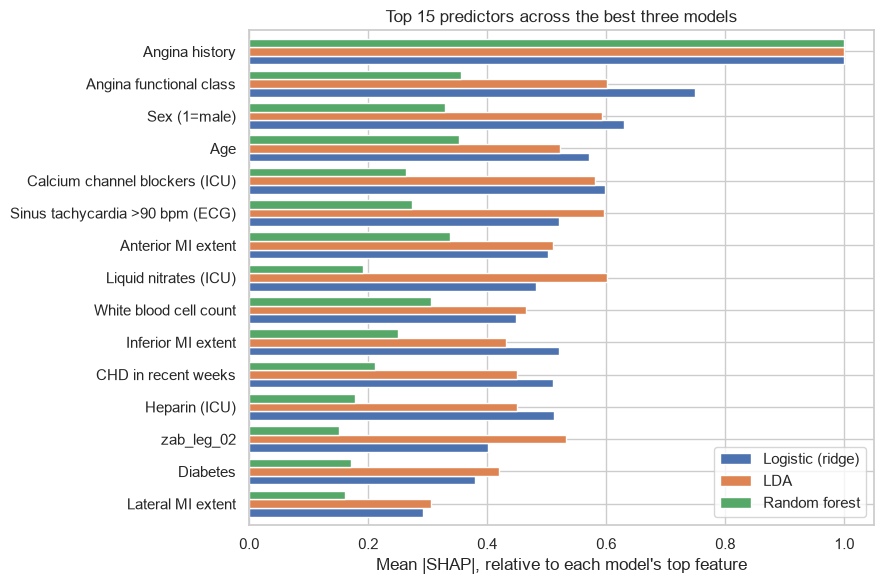

Rank of each feature within each model:


,Logistic (ridge),LDA,Random forest
Angina history,1,1,1
Angina functional class,2,3,2
Sex (1=male),3,5,5
Age,5,8,3
Calcium channel blockers (ICU),4,6,8
Sinus tachycardia >90 bpm (ECG),6,4,7
Anterior MI extent,10,9,4
Liquid nitrates (ICU),11,2,12
White blood cell count,12,10,6
Inferior MI extent,7,13,9


In [15]:
imp = pd.DataFrame({n: pd.Series(np.abs(shap_values[n].values).mean(0),
                                 index=shap_values[n].feature_names) for n in TOP3})
imp_rel = imp / imp.max()
top_feats = imp_rel.mean(axis=1).sort_values(ascending=False).head(15).index
fig, ax = plt.subplots(figsize=(9, 6))
imp_rel.loc[top_feats[::-1]].plot.barh(ax=ax, width=0.8)
ax.set_xlabel("Mean |SHAP|, relative to each model's top feature")
ax.set_title("Top 15 predictors across the best three models")
plt.tight_layout(); plt.show()

rank = imp.rank(ascending=False).loc[top_feats].astype(int)
print("Rank of each feature within each model:")
rank

### Interpretation — SHAP
* **All three models agree on the top features:** **angina history** and **angina functional class** rank #1–3 in every model. Then come **male sex**, **age**, **sinus tachycardia** on the admission ECG, and **MI location/extent** (anterior, inferior).
* The story is clinically coherent: patients with **pre-existing, symptomatic coronary disease** (angina, recent CHD) have more vulnerable plaque elsewhere, so they are more likely to re-infarct.
* **ICU treatments** (calcium-channel blockers, nitrates, heparin) rank high. These reflect **confounding by indication**: clinicians give them to patients who look ischemic. They are markers of perceived risk, not causes.
* With weak overall signal, individual SHAP values are small and noisy. Treat the *shared* top features as the robust finding, not exact rankings.

## 7. Over- and underfitting

* **Overfitting** shows up as a large gap between training AUC and nested CV / test AUC.
* **Underfitting** shows up as *low* training AUC (the model cannot fit even the data it saw), or honest AUC well below the best model.
* Caveat: KNN with distance weighting and fully grown trees score ~1.0 on training data by construction (each training patient is its own nearest neighbour / own leaf), so for these models the *nested CV and test* AUC are what matter.
* Nested CV and test AUC should agree within sampling error; the test set has only ~32 cases, so its AUC is noisy (see the CI width).

In [16]:
fit_table = cv_table[["Model", "Train AUC", "Inner CV AUC (tuned)", "Nested CV AUC"]].merge(
    test_table[["Model", "ROC-AUC"]].rename(columns={"ROC-AUC": "Test AUC"}), on="Model")
fit_table["Train − Nested gap"] = fit_table["Train AUC"] - fit_table["Nested CV AUC"]
fit_table["Optimism (inner − nested)"] = fit_table["Inner CV AUC (tuned)"] - fit_table["Nested CV AUC"]

# Rules of thumb for a weak-signal outcome (best nested AUC ≈ 0.65):
#   underfitting = cannot fit even the training data well, AND clearly below the best honest AUC
#   overfitting  = large train − nested gap
best_nested = fit_table["Nested CV AUC"].max()
def diagnose(r):
    if r["Train AUC"] < 0.70 or r["Nested CV AUC"] < best_nested - 0.05:
        return "Underfitting / poor fit"
    if r["Train − Nested gap"] > 0.20:
        return "Overfitting (memorizes training data)"
    if r["Train − Nested gap"] > 0.08:
        return "Mild overfitting (controlled by penalty)"
    return "Good fit"
fit_table["Diagnosis"] = fit_table.apply(diagnose, axis=1)
fit_table.round(3)

,Model,Train AUC,Inner CV AUC (tuned),Nested CV AUC,Test AUC,Train − Nested gap,Optimism (inner − nested),Diagnosis
0,Logistic (ridge),0.760,0.624,0.653,0.612,0.106,-0.029,Mild overfitting (controlled by penalty)
1,LDA,0.759,0.624,0.653,0.613,0.106,-0.029,Mild overfitting (controlled by penalty)
2,Random forest,0.980,0.654,0.651,0.583,0.329,0.003,Overfitting (memorizes training data)
3,Spline logistic,0.769,0.627,0.648,0.634,0.121,-0.021,Mild overfitting (controlled by penalty)
4,Elastic net,0.731,0.618,0.634,0.585,0.097,-0.017,Mild overfitting (controlled by penalty)
5,Lasso logistic,0.761,0.622,0.625,0.603,0.135,-0.003,Mild overfitting (controlled by penalty)
6,Gradient boosting,0.841,0.636,0.623,0.556,0.218,0.013,Overfitting (memorizes training data)
7,KNN,1.000,0.636,0.607,0.627,0.393,0.029,Overfitting (memorizes training data)
8,Naive Bayes,0.730,0.542,0.580,0.633,0.150,-0.037,Underfitting / poor fit
9,QDA,0.599,0.564,0.561,0.508,0.038,0.003,Underfitting / poor fit


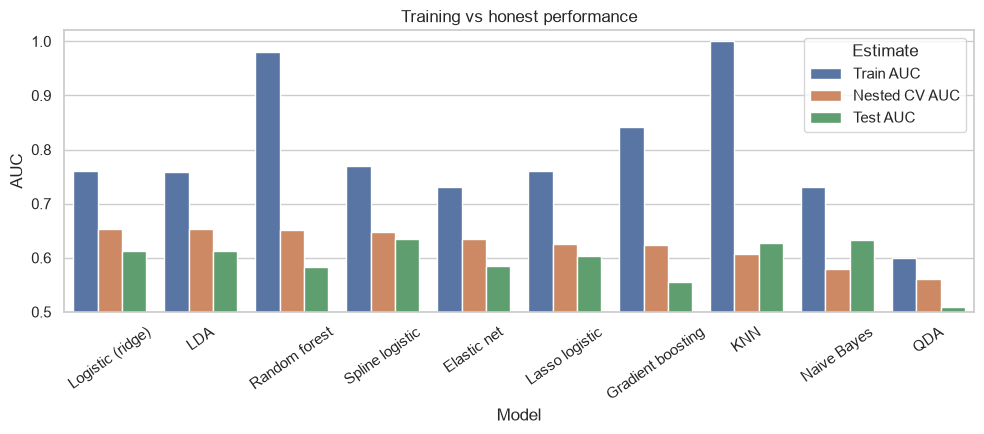

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_df = fit_table.melt(id_vars="Model", value_vars=["Train AUC", "Nested CV AUC", "Test AUC"],
                         var_name="Estimate", value_name="AUC")
sns.barplot(data=plot_df, x="Model", y="AUC", hue="Estimate", ax=ax)
ax.set_ylim(0.5, 1.02); ax.tick_params(axis="x", rotation=35); ax.set_title("Training vs honest performance")
plt.tight_layout(); plt.show()

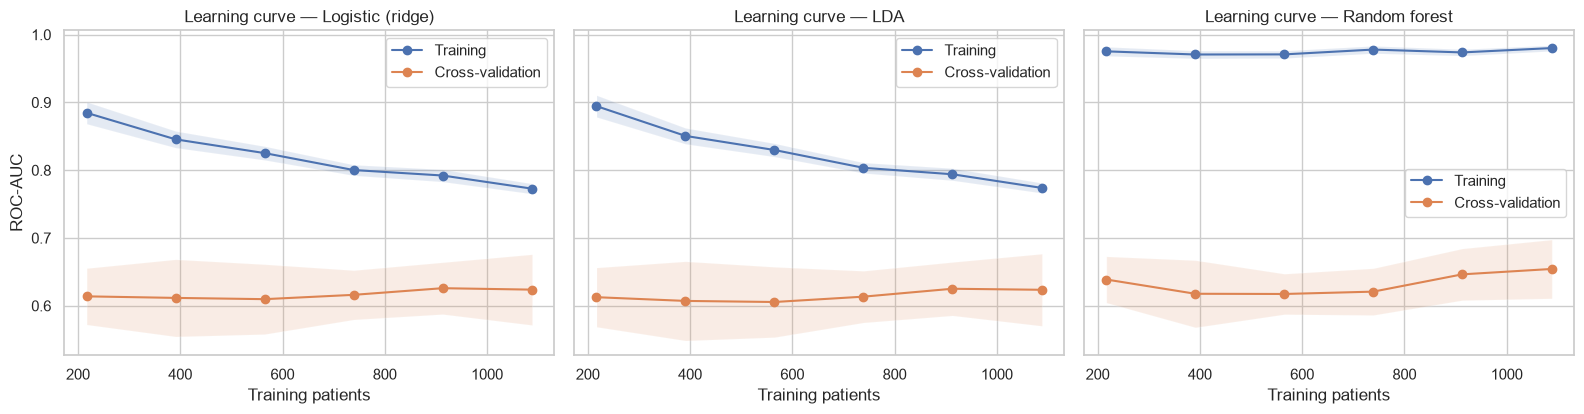

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, name in zip(axes, TOP3):
    sizes, tr, va = learning_curve(fitted[name], X_train, y_train, cv=inner_cv, scoring="roc_auc",
                                   train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1)
    for s, lab in [(tr, "Training"), (va, "Cross-validation")]:
        ax.plot(sizes, s.mean(1), "o-", label=lab)
        ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.15)
    ax.set_title(f"Learning curve — {name}"); ax.set_xlabel("Training patients"); ax.legend()
axes[0].set_ylabel("ROC-AUC")
plt.tight_layout(); plt.show()

### Bias–variance in action: KNN's *k* and the lasso penalty
Small *k* / weak penalty → training AUC near 1 but poor validation (overfit). Large *k* / strong penalty → both drop (underfit).

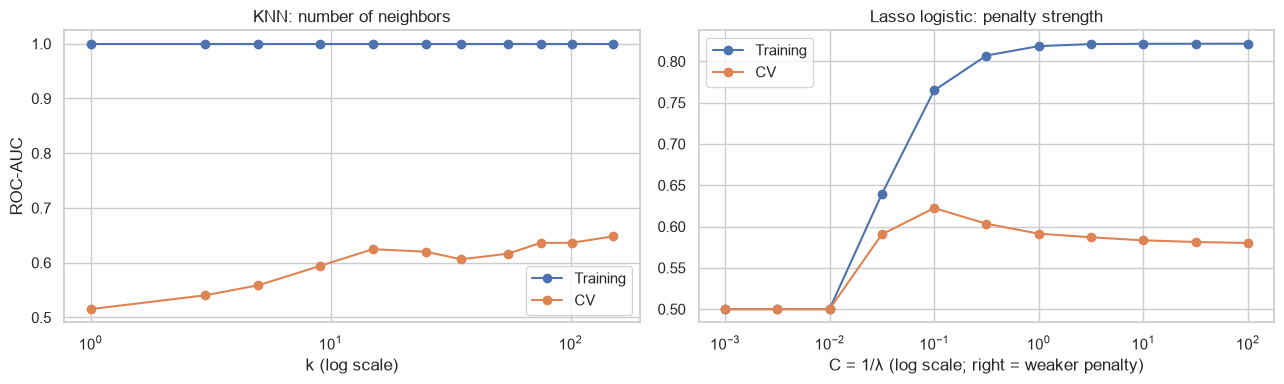

Lasso keeps 41 of 100 predictors (best C = 0.1)


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
knn_pipe = fitted["KNN"]
ks = [1, 3, 5, 9, 15, 25, 35, 55, 75, 101, 151]
tr, va = validation_curve(knn_pipe, X_train, y_train, param_name="clf__n_neighbors", param_range=ks,
                          cv=inner_cv, scoring="roc_auc", n_jobs=-1)
axes[0].plot(ks, tr.mean(1), "o-", label="Training"); axes[0].plot(ks, va.mean(1), "o-", label="CV")
axes[0].set_xscale("log"); axes[0].set_xlabel("k (log scale)"); axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("KNN: number of neighbors"); axes[0].legend()

Cs = np.logspace(-3, 2, 11)
tr, va = validation_curve(fitted["Lasso logistic"], X_train, y_train, param_name="clf__C", param_range=Cs,
                          cv=inner_cv, scoring="roc_auc", n_jobs=-1)
axes[1].plot(Cs, tr.mean(1), "o-", label="Training"); axes[1].plot(Cs, va.mean(1), "o-", label="CV")
axes[1].set_xscale("log"); axes[1].set_xlabel("C = 1/λ (log scale; right = weaker penalty)")
axes[1].set_title("Lasso logistic: penalty strength"); axes[1].legend()
plt.tight_layout(); plt.show()

lasso = fitted["Lasso logistic"].named_steps["clf"]
print(f"Lasso keeps {np.sum(lasso.coef_ != 0)} of {len(FEATURES)} predictors (best C = {lasso.C:.3g})")

### Interpretation — fit
* **Linear/LDA/spline models:** train AUC ≈0.73–0.77 vs nested ≈0.63–0.65. The strong penalties chosen by CV keep this gap modest, and their learning curves flatten, so more data would help only slightly. The limit is the predictors.
* **Random forest and gradient boosting overfit:** train AUC 0.98 / 0.84 vs test 0.58 / 0.56. With 127 training cases, flexible models memorize noise.
* **KNN's** training AUC of 1.0 is an artifact of distance weighting. CV picked the largest k in the grid (75), which shows that heavy smoothing was needed.
* **QDA and Naive Bayes underfit:** their assumptions (class-specific covariance, conditional independence) do not fit 100 mostly-binary predictors with few cases.
* Test AUCs run ~0.03–0.07 below nested CV for most models. That is within the wide test CI, and nested CV (5 folds, 127 cases) is the more stable estimate.

## 8. Data-leakage assessment

We check for leakage in six ways.

**8a. Procedural leakage (by design).** Test set split off first; imputation, scaling and spline bases are inside pipelines and re-fit in every CV fold; the >70% missing rule used training data only; thresholds came from training OOF predictions; model ranking used nested CV, not the test set.

**8b. Duplicates.** No duplicate IDs or duplicate patient rows (checked in Section 2), so the same patient cannot appear in both training and test data.

**8c. Temporal leakage experiment.** Refit the best model *including* the nine day-1 to day-3 variables (pain relapse, opioids, NSAIDs). Recurrent chest pain on days 1–3 can be the *symptom of the recurrent MI itself*, so these variables are a potential proxy for the outcome.

In [20]:
best_name = TOP3[0]
LEAKY = [c for c in ALL_INPUTS if c not in too_sparse]
cont_saved, coded_saved = CONTINUOUS, CODED
CODED = [c for c in LEAKY if c not in CONTINUOUS]           # preprocessor() reads these globals
leaky_pipe, leaky_grid = MODELS[best_name]
leaky_pipe = make_pipe(leaky_pipe.named_steps["clf"], spline=(best_name == "Spline logistic"))
gs_leaky = GridSearchCV(leaky_pipe, leaky_grid, scoring="roc_auc", cv=inner_cv, n_jobs=-1)
gs_leaky.fit(X_train_all[LEAKY], y_train)
leaky_auc = roc_auc_score(y_test, gs_leaky.predict_proba(X_test_all[LEAKY])[:, 1])
CODED = coded_saved

# Same model, post-admission variables + a missing-value indicator for each (what many default pipelines do)
leaky_ind = Pipeline([("prep", ColumnTransformer([
        ("cont", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), CONTINUOUS),
        ("coded", Pipeline([("impute", SimpleImputer(strategy="most_frequent", add_indicator=True)),
                            ("scale", StandardScaler())]), [c for c in LEAKY if c not in CONTINUOUS])])),
    ("clf", clone(fitted[best_name].named_steps["clf"]))])
leaky_ind.fit(X_train_all[LEAKY], y_train)
leaky_ind_auc = roc_auc_score(y_test, leaky_ind.predict_proba(X_test_all[LEAKY])[:, 1])
print(f"{best_name}: test AUC with post-admission variables + missing indicators = {leaky_ind_auc:.3f}")

print(f"{best_name}: test AUC admission-only = {test_table.set_index('Model').loc[best_name, 'ROC-AUC']:.3f}"
      f" | with post-admission variables = {leaky_auc:.3f}")

# Is missingness of the day-1 to day-3 variables related to the outcome?
miss_by_outcome = df.groupby("Y")[POST_ADMISSION].apply(lambda d: d.isna().mean()).T
miss_by_outcome.columns = ["Missing | no re-MI", "Missing | re-MI"]
miss_by_outcome.round(3)

Logistic (ridge): test AUC with post-admission variables + missing indicators = 0.646
Logistic (ridge): test AUC admission-only = 0.612 | with post-admission variables = 0.613


,Missing | no re-MI,Missing | re-MI
R_AB_1_n,0.010,0.000
R_AB_2_n,0.069,0.006
R_AB_3_n,0.082,0.006
NA_R_1_n,0.003,0.006
NA_R_2_n,0.069,0.013
NA_R_3_n,0.084,0.013
NOT_NA_1_n,0.006,0.006
NOT_NA_2_n,0.070,0.013
NOT_NA_3_n,0.084,0.013


**8d. Target leakage from other complications.** How strongly do the other in-hospital outcomes "predict" recurrent MI? A high AUC here shows why they must never be used as predictors.

In [21]:
other = [c for c in OUTCOMES if c not in (OUTCOME, "LET_IS")] + ["DEATH"]
leak_scan = pd.Series({c: roc_auc_score(df.Y, df[c]) for c in other}).sort_values(ascending=False)
leak_scan.round(3).to_frame("AUC vs recurrent MI (if used as predictor)")

,AUC vs recurrent MI (if used as predictor)
OTEK_LANC,0.587
DEATH,0.572
ZSN,0.563
FIBR_PREDS,0.521
FIBR_JELUD,0.515
P_IM_STEN,0.514
JELUD_TAH,0.514
PREDS_TAH,0.504
DRESSLER,0.503
A_V_BLOK,0.502


**8e. Suspiciously strong single predictors.** A single admission-time feature with AUC ≳ 0.9 would be a red flag for a proxy of the outcome. We scan every feature (training data, median-imputed, AUC flipped so ≥ 0.5).

In [22]:
uni = {}
for c in FEATURES:
    x = X_train[c].fillna(X_train[c].median())
    if x.nunique() > 1:
        a = roc_auc_score(y_train, x)
        uni[c] = max(a, 1 - a)
uni = pd.Series(uni).sort_values(ascending=False)
print("Max single-feature AUC:", round(uni.max(), 3), "→", "red flag" if uni.max() > 0.9 else "no red flag")
uni.head(10).rename(index=LABELS).round(3).to_frame("Univariate AUC")

Max single-feature AUC: 0.623 → no red flag


,Univariate AUC
Angina history,0.623
Angina functional class,0.586
Age,0.580
CHD in recent weeks,0.567
Sex (1=male),0.561
Anterior MI extent,0.560
Inferior MI extent,0.559
Lateral MI extent,0.558
Sinus tachycardia >90 bpm (ECG),0.555
Calcium channel blockers (ICU),0.550


**8f. ID / row-order check.** Row ID should carry no signal. If it does, the file is sorted by outcome, and any split that follows row order (e.g. "first 80% for training") would train on a different population than it tests on.

AUC of ID alone: 0.727


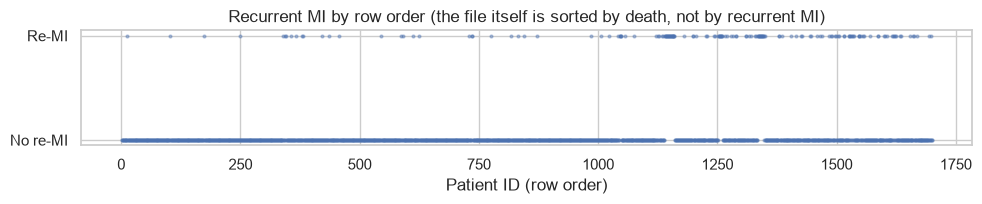

KFold, no shuffle (row order)            re-MI rate per test fold: [0.01 0.04 0.03 0.23 0.16]
StratifiedKFold, shuffled (used here)    re-MI rate per test fold: [0.09 0.09 0.09 0.09 0.09]


In [23]:
print("AUC of ID alone:", round(max(roc_auc_score(df.Y, df.ID), 1 - roc_auc_score(df.Y, df.ID)), 3))

fig, ax = plt.subplots(figsize=(10, 2.2))
ax.scatter(df.ID, df.Y, s=4, alpha=0.4)
ax.set_xlabel("Patient ID (row order)"); ax.set_yticks([0, 1]); ax.set_yticklabels(["No re-MI", "Re-MI"])
ax.set_title("Recurrent MI by row order (the file itself is sorted by death, not by recurrent MI)")
plt.tight_layout(); plt.show()

# What an unshuffled split does: folds become (nearly) single-class, so performance estimates break
from sklearn.model_selection import KFold
demo = make_pipe(LogisticRegression(l1_ratio=0, max_iter=5000, C=0.1))
for label, cv in [("KFold, no shuffle (row order)", KFold(5, shuffle=False)),
                  ("StratifiedKFold, shuffled (used here)", StratifiedKFold(5, shuffle=True, random_state=SEED))]:
    folds = list(cv.split(df[FEATURES], df.Y))
    rates = [df.Y.iloc[te].mean() for _, te in folds]
    print(f"{label:<40} re-MI rate per test fold: {np.round(rates, 2)}")

## 9. Summary
The final cell prints the key results; interpretation is in the markdown discussion below.

In [24]:
summary = cv_table[["Model", "Nested CV AUC"]].merge(
    test_table[["Model", "ROC-AUC", "AUC 95% CI", "PR-AUC", "Brier", "Balanced acc", "Sensitivity",
                "Specificity", "MCC"]], on="Model").merge(fit_table[["Model", "Diagnosis"]], on="Model")
summary.round(3)

,Model,Nested CV AUC,ROC-AUC,AUC 95% CI,PR-AUC,Brier,Balanced acc,Sensitivity,Specificity,MCC,Diagnosis
0,Logistic (ridge),0.653,0.612,0.501–0.720,0.174,0.084,0.600,0.469,0.731,0.128,Mild overfitting (controlled by penalty)
1,LDA,0.653,0.613,0.502–0.720,0.174,0.097,0.595,0.469,0.721,0.121,Mild overfitting (controlled by penalty)
2,Random forest,0.651,0.583,0.461–0.695,0.184,0.084,0.588,0.656,0.519,0.103,Overfitting (memorizes training data)
3,Spline logistic,0.648,0.634,0.520–0.745,0.209,0.084,0.613,0.531,0.695,0.141,Mild overfitting (controlled by penalty)
4,Elastic net,0.634,0.585,0.473–0.689,0.152,0.084,0.562,0.469,0.656,0.076,Mild overfitting (controlled by penalty)
5,Lasso logistic,0.625,0.603,0.491–0.712,0.165,0.084,0.588,0.625,0.552,0.104,Mild overfitting (controlled by penalty)
6,Gradient boosting,0.623,0.556,0.445–0.656,0.143,0.085,0.495,0.500,0.490,-0.006,Overfitting (memorizes training data)
7,KNN,0.607,0.627,0.508–0.733,0.173,0.084,0.547,0.656,0.438,0.056,Overfitting (memorizes training data)
8,Naive Bayes,0.580,0.633,0.526–0.735,0.136,0.811,0.490,0.094,0.886,-0.018,Underfitting / poor fit
9,QDA,0.561,0.508,0.403–0.604,0.102,0.222,0.488,0.281,0.695,-0.015,Underfitting / poor fit


### Leakage findings
1. **No procedural leakage.** Preprocessing lives inside pipelines; the missingness rule and thresholds used training data only; ranking used nested CV; the test set was used once.
2. **Day 1–3 variables:** they are weak predictors of recurrent MI (univariate AUC ≤ 0.57), and adding them barely changes test AUC (0.612 → 0.613). With missing-value **indicators**, AUC rises to 0.646. The day 2–3 variables are missing more often among patients *without* re-MI (7–8% vs ~1%), so the model is partly learning *who stayed in hospital long enough to be recorded*. That is still leakage, and they stay excluded.
3. **The file is sorted by death,** and death is correlated with re-MI, so **row ID alone has AUC 0.73** for recurrent MI. An unshuffled split would give folds with re-MI rates from 1% to 23%. Shuffled, stratified splits fix this, and ID is excluded.
4. **Other in-hospital outcomes** (pulmonary edema, death, heart failure, …) are excluded. None is a strong proxy (AUC ≤ 0.59), but they are not known at admission.
5. **No hidden proxy:** max single-feature AUC is 0.62.

## Conclusions
* **Best three algorithms (nested CV): ridge logistic regression, LDA, random forest**, effectively tied with spline logistic. On the test set, spline logistic did best (AUC 0.634, PR-AUC 0.209).
* **Main finding:** admission-time clinical data predict in-hospital recurrent MI only modestly (AUC ≈ 0.65). That is far weaker than the same data predict mortality (≈ 0.89). Angina history and angina severity are the most consistent predictors.
* **Model choice matters less than information.** A strongly penalized logistic model matches or beats ensembles and is easier to explain.
* **Limitations:** single-centre data (1992–1995); only 159 cases (32 in test); ordinal codes treated as numeric; **death is a competing risk** (46 of 159 re-MI patients died, and early deaths may hide recurrences); thresholds set by Youden's J rather than clinical costs; no external validation.
* **Next steps:** add biomarkers that are absent here (troponin, LDL), angiography or revascularization data, and a competing-risk time-to-event model.